# Alignment & RLHF: DPO, PPO, and GRPO

The main tutorial (`../LLM_Fine_Tuning_Tutorial.ipynb`) covers **supervised** fine-tuning: the model imitates reference outputs. Alignment methods go one step further and optimize the model toward outputs that are *preferred*, using either preference pairs or a reward signal.

This notebook implements three of them on the same task so that they can be compared directly:

| Method | Learns from | Models needed during training | Online sampling? |
|---|---|---|---|
| **DPO** (Direct Preference Optimization) | pairs of (chosen, rejected) responses | policy + frozen reference | no |
| **PPO** (Proximal Policy Optimization, classic RLHF) | a reward model's scores | policy + reference + reward model + value function | yes |
| **GRPO** (Group Relative Policy Optimization) | a reward function's scores within a group of samples | policy (+ reference if `beta > 0`) + reward function | yes |

**Task.** Starting from `lvwerra/gpt2-imdb` (GPT-2 already fine-tuned on IMDB reviews, i.e. our "SFT model"), steer the model to continue movie-review prompts **positively**. A sentiment classifier, `lvwerra/distilbert-imdb`, plays the role of the reward model. This is the classic TRL sentiment-steering demo; it is small enough to run on a CPU.

> Libraries: Hugging Face [TRL](https://huggingface.co/docs/trl) provides `DPOTrainer` and `GRPOTrainer`. TRL 1.x no longer ships a `PPOTrainer`, so Section 5 implements PPO from scratch in about 80 lines, which also makes its four components explicit. [Axolotl](https://github.com/axolotl-ai-cloud/axolotl) exposes the same preference and RL methods (`rl: dpo`, `rl: grpo`, ...) through YAML configs if you prefer a config-driven workflow.
>
> Last run with TRL 1.16, transformers 5.20, PyTorch 2.10 (CPU).

## 0. Environment Setup

Uncomment and run once if the packages are missing:

In [1]:
# %pip install -U trl transformers datasets accelerate matplotlib

## 1. Policy, Reference, Reward Model, and Prompts

- **Policy:** the model we train (a fresh copy of the SFT model for every method).
- **Reference:** a frozen copy of the SFT model. Every method below keeps the policy close to it (a KL penalty in PPO and GRPO, an implicit one in DPO), so the model keeps writing fluent reviews instead of collapsing onto whatever the reward model likes.
- **Reward:** the sentiment classifier's logit margin, `logit(POSITIVE) - logit(NEGATIVE)`, on prompt + completion. Higher means more positive.
- **Prompts:** the first 8 tokens of IMDB reviews. The training prompts come from the IMDB train split; the 64 evaluation prompts come from the test split.

In [2]:
import copy, time
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import transformers, trl
from datasets import load_dataset, Dataset
from transformers import AutoModelForCausalLM, AutoModelForSequenceClassification, AutoTokenizer, set_seed

SEED = 42
set_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_BF16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
print("PyTorch:", torch.__version__, "| Transformers:", transformers.__version__, "| TRL:", trl.__version__, "| device:", DEVICE)

SFT_NAME    = "lvwerra/gpt2-imdb"         # policy starting point / reference
REWARD_NAME = "lvwerra/distilbert-imdb"   # reward model (sentiment classifier)

tok = AutoTokenizer.from_pretrained(SFT_NAME)
tok.pad_token = tok.eos_token
tok.padding_side = "left"                 # decoder-only models generate after the prompt

def load_sft():
    model = AutoModelForCausalLM.from_pretrained(SFT_NAME)
    model.config.pad_token_id = tok.pad_token_id
    model.generation_config.pad_token_id = tok.pad_token_id
    return model.to(DEVICE)

ref_model = load_sft().eval()
for p in ref_model.parameters():
    p.requires_grad = False

reward_tok   = AutoTokenizer.from_pretrained(REWARD_NAME)
reward_model = AutoModelForSequenceClassification.from_pretrained(REWARD_NAME).to(DEVICE).eval()
POS = reward_model.config.label2id["POSITIVE"]
NEG = reward_model.config.label2id["NEGATIVE"]

@torch.no_grad()
def sentiment_reward(texts, batch_size=64):
    scores = []
    for i in range(0, len(texts), batch_size):
        enc = reward_tok(texts[i:i + batch_size], return_tensors="pt", padding=True,
                         truncation=True, max_length=512).to(DEVICE)
        logits = reward_model(**enc).logits
        scores += (logits[:, POS] - logits[:, NEG]).tolist()
    return scores

print(sentiment_reward(["This movie was wonderful!", "This movie was a waste of time."]))

PyTorch: 2.10.0+cpu | Transformers: 5.20.2 | TRL: 1.16.0 | device: cpu


[5.2240705490112305, -5.7768354415893555]


In [3]:
imdb = load_dataset("imdb")

def make_prompts(split, n, offset=0):
    texts = imdb[split].shuffle(seed=SEED).select(range(offset, offset + 4 * n))["text"]
    prompts = []
    for t in texts:
        ids = tok(t.replace("<br />", " ")[:200])["input_ids"][:8]
        prompts.append(tok.decode(ids))
        if len(prompts) == n:
            break
    return prompts

train_prompts = make_prompts("train", 256)
eval_prompts  = make_prompts("test", 64)
print(train_prompts[:4])

['There is no relation at all between Fort', 'This movie is a great. The plot', 'George P. Cosmatos\' "', 'In the process of trying to establish the']


### 1.1 Shared helpers: sampling, log-probabilities, evaluation

`rollout` samples completions and returns the token ids plus a mask that covers each completion up to and including its first EOS. `completion_logprobs` scores those tokens under any model; we use it for the KL to the reference (all methods) and for the PPO update (Section 5).

`evaluate_policy` reports, on the 64 held-out prompts:
- **mean reward** and **% positive** (reward > 0), which is what we optimize;
- **KL to reference**, the summed per-token log-ratio log π(y|x) − log π_ref(y|x) averaged over samples, which measures how far the policy drifted from the SFT model.

In [4]:
GEN_KW = dict(max_new_tokens=24, do_sample=True, top_k=0, top_p=1.0, temperature=1.0)

@torch.no_grad()
def rollout(model, prompts):
    enc = tok(prompts, return_tensors="pt", padding=True).to(DEVICE)
    out = model.generate(**enc, **GEN_KW, pad_token_id=tok.eos_token_id)
    n_prompt = enc["input_ids"].shape[1]
    comp = out[:, n_prompt:]
    is_eos = (comp == tok.eos_token_id).long()
    comp_mask = (is_eos.cumsum(-1) - is_eos) == 0          # tokens up to and including the first EOS
    attn = torch.cat([enc["attention_mask"], comp_mask.long()], dim=1)
    texts = tok.batch_decode(comp.masked_fill(~comp_mask, tok.eos_token_id), skip_special_tokens=True)
    return out, attn, n_prompt, comp_mask.float(), texts

def completion_logprobs(model, ids, attn, n_prompt, return_hidden=False):
    pos = (attn.cumsum(-1) - 1).clamp(min=0)                # position ids that skip left padding
    out = model(input_ids=ids, attention_mask=attn, position_ids=pos, output_hidden_states=return_hidden)
    logits = out.logits[:, n_prompt - 1:-1].float()         # logits that predict the completion tokens
    logp = torch.log_softmax(logits, dim=-1).gather(-1, ids[:, n_prompt:, None]).squeeze(-1)
    if return_hidden:
        return logp, out.hidden_states[-1][:, n_prompt - 1:-1]
    return logp

RESULTS, SAMPLES = [], {}

@torch.no_grad()
def evaluate_policy(model, method, train_seconds=0.0, batch_size=32):
    model.eval()
    set_seed(SEED)
    rewards, kls, texts = [], [], []
    for i in range(0, len(eval_prompts), batch_size):
        prompts = eval_prompts[i:i + batch_size]
        ids, attn, n_prompt, mask, comps = rollout(model, prompts)
        lp, lp_ref = completion_logprobs(model, ids, attn, n_prompt), completion_logprobs(ref_model, ids, attn, n_prompt)
        kls += ((lp - lp_ref) * mask).sum(-1).tolist()
        rewards += sentiment_reward([p + c for p, c in zip(prompts, comps)])
        texts += comps
    SAMPLES[method] = texts
    row = {"method": method, "mean reward": np.mean(rewards), "% positive": 100 * np.mean(np.array(rewards) > 0),
           "KL to reference": np.mean(kls), "train time (s)": round(train_seconds, 1)}
    RESULTS.append(row)
    print(row)
    return row

evaluate_policy(ref_model, "SFT model (no alignment)");

{'method': 'SFT model (no alignment)', 'mean reward': np.float64(0.3186867772601545), '% positive': np.float64(54.6875), 'KL to reference': np.float64(0.0), 'train time (s)': 0.0}


## 2. Where the Reward Model Comes From

In real RLHF the reward model is trained on human preference pairs: given a prompt, a *chosen* and a *rejected* response, it learns a scalar score with the Bradley-Terry loss −log σ(r(x, y_chosen) − r(x, y_rejected)). TRL's `RewardTrainer` does this from a dataset with `chosen` / `rejected` columns:

```python
from trl import RewardTrainer, RewardConfig
trainer = RewardTrainer(model="distilbert-base-uncased", args=RewardConfig(output_dir="rm"),
                        train_dataset=preference_pairs, processing_class=tokenizer)
```

Here we skip that step and use an off-the-shelf sentiment classifier as the reward model, so the "human preference" is simply *more positive is better*.

## 3. DPO: Direct Preference Optimization

DPO skips the reward model and the RL loop. Given preference pairs, it directly increases the likelihood of the chosen response relative to the rejected one, measured against the frozen reference:

$$\mathcal{L}_{\text{DPO}} = -\log \sigma\Big(\beta \big[\log \tfrac{\pi(y_c|x)}{\pi_{\text{ref}}(y_c|x)} - \log \tfrac{\pi(y_r|x)}{\pi_{\text{ref}}(y_r|x)}\big]\Big)$$

The term inside σ is an *implicit reward margin*; β controls how far the policy may move from the reference.

**Building the pairs.** DPO needs `prompt`, `chosen`, `rejected` columns. With no human labels at hand, we sample 4 completions per training prompt from the SFT model, score them with the reward model, and keep the best as *chosen* and the worst as *rejected* (the pattern used for AI-feedback datasets such as UltraFeedback). The same format works for any human-labelled preference dataset, e.g. `trl-lib/ultrafeedback_binarized`.

In [5]:
set_seed(SEED)
pairs = []
for i in range(0, len(train_prompts), 32):
    prompts = train_prompts[i:i + 32]
    group = [prompts[j // 4] for j in range(4 * len(prompts))]      # 4 samples per prompt
    *_, comps = rollout(ref_model, group)
    scores = np.array(sentiment_reward([p + c for p, c in zip(group, comps)])).reshape(-1, 4)
    for k, prompt in enumerate(prompts):
        best, worst = scores[k].argmax(), scores[k].argmin()
        pairs.append({"prompt": prompt, "chosen": comps[4 * k + best], "rejected": comps[4 * k + worst],
                      "reward_gap": scores[k, best] - scores[k, worst]})

dpo_ds = Dataset.from_list(pairs)
print(dpo_ds)
print("mean reward gap chosen - rejected:", np.mean(dpo_ds["reward_gap"]).round(2))
print(dpo_ds[0])
dpo_ds = dpo_ds.remove_columns("reward_gap").train_test_split(test_size=0.1, seed=SEED)

Dataset({
    features: ['prompt', 'chosen', 'rejected', 'reward_gap'],
    num_rows: 256
})
mean reward gap chosen - rejected: 4.76
{'prompt': 'There is no relation at all between Fort', 'chosen': " Pitt and the Masters of Horror. It's a pure fiction mode.<br /><br />5/10", 'rejected': ' McMurray and this movie. It completely contradicts itself. You see all the props in the book. What a hack', 'reward_gap': 5.717034816741943}


In [6]:
from trl import DPOConfig, DPOTrainer

set_seed(SEED)
dpo_policy = load_sft()

dpo_args = DPOConfig(
    output_dir="./align_dpo",
    beta=0.1,                        # strength of the pull towards the reference
    learning_rate=2e-5,
    num_train_epochs=3,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    max_length=64,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=10,
    bf16=USE_BF16,
    report_to="none",
    seed=SEED,
)

dpo_trainer = DPOTrainer(
    model=dpo_policy,
    ref_model=ref_model,             # if None, TRL makes a frozen copy of the policy
    args=dpo_args,
    train_dataset=dpo_ds["train"],
    eval_dataset=dpo_ds["test"],
    processing_class=tok,
)

t0 = time.time()
dpo_trainer.train()
dpo_seconds = time.time() - t0

# Preference accuracy and implicit reward margin on held-out pairs
dpo_eval = dpo_trainer.evaluate()
print({k: round(v, 3) for k, v in dpo_eval.items() if "rewards" in k or k == "eval_loss"})

evaluate_policy(dpo_policy, "DPO", dpo_seconds);

Epoch,Training Loss,Validation Loss,Entropy,Num Tokens,Logits/chosen,Logits/rejected,Mean Token Accuracy,Rewards/chosen,Rewards/rejected,Rewards/accuracies,Rewards/margins,Logps/chosen,Logps/rejected
1,0.659543,0.560953,3.678828,14755.000000,-29.930801,-27.801412,0.316796,0.010253,-0.247858,0.812500,0.258111,-92.031395,-98.906614
2,0.281261,0.482958,3.447486,29510.000000,-30.291867,-27.485527,0.320381,-0.110552,-0.589011,0.875000,0.478459,-93.239445,-102.318142
3,0.161798,0.459519,3.349746,44265.000000,-30.104279,-27.030376,0.321357,-0.201059,-0.758729,0.843750,0.557671,-94.144503,-104.015324


Training Loss,Validation Loss,Epoch,Entropy,Num Tokens,Logits/chosen,Logits/rejected,Mean Token Accuracy,Rewards/chosen,Rewards/rejected,Rewards/accuracies,Rewards/margins,Logps/chosen,Logps/rejected
0.161798,0.459519,3,3.349746,44265.000000,-30.104279,-27.030376,0.321357,-0.201059,-0.758729,0.843750,0.557671,-94.144503,-104.015324


{'eval_loss': 0.46, 'eval_rewards/chosen': -0.201, 'eval_rewards/rejected': -0.759, 'eval_rewards/accuracies': 0.844, 'eval_rewards/margins': 0.558}


{'method': 'DPO', 'mean reward': np.float64(3.270302949938923), '% positive': np.float64(87.5), 'KL to reference': np.float64(3.9356477386318147), 'train time (s)': 268.5}


## 4. Generating Rewards Online: PPO and GRPO

DPO learns from a fixed dataset. PPO and GRPO are **online**: in every step the current policy samples completions, the reward model scores them, and the policy is updated towards higher-reward samples. The two differ in how they turn rewards into a learning signal (the *advantage* of each sample):

- **PPO** trains a **value function** (critic) that predicts the expected reward, and uses reward minus predicted value as the advantage.
- **GRPO** drops the critic. It samples a **group** of G completions per prompt and uses each sample's reward relative to its group: A_i = (r_i − mean(r)) / std(r).

In [7]:
# GRPO's group-relative advantage on a toy group of 4 completions for one prompt
r = torch.tensor([2.5, -1.0, 0.5, 3.0])
print("rewards:   ", r.tolist())
print("advantages:", ((r - r.mean()) / (r.std() + 1e-4)).round(decimals=2).tolist())

rewards:    [2.5, -1.0, 0.5, 3.0]
advantages: [0.6800000071525574, -1.2200000286102295, -0.4099999964237213, 0.949999988079071]


## 5. PPO: Classic RLHF (from scratch)

The four models of PPO-based RLHF:
1. **Policy** π: the SFT model being trained.
2. **Reference** π_ref: frozen SFT model; a per-token KL penalty −β·(log π − log π_ref) is added to the reward.
3. **Reward model**: scores the finished completion (added at its last token).
4. **Value function** V: a linear head on the policy's last hidden state that predicts the return at every token (like TRL's former `AutoModelForCausalLMWithValueHead`).

Each iteration:
1. **Rollout:** sample completions for a batch of prompts; record their log-probs under the policy and reference, the values, and the rewards.
2. **Advantages:** generalized advantage estimation (GAE) over the completion tokens, then normalize.
3. **Update:** a few epochs of the clipped surrogate objective, min(ρA, clip(ρ, 1−ε, 1+ε)A) with ρ = π/π_old, plus a value-regression loss.

In [8]:
class PolicyWithValueHead(torch.nn.Module):
    def __init__(self, lm):
        super().__init__()
        self.lm = lm
        self.v_head = torch.nn.Linear(lm.config.n_embd, 1)
        torch.nn.init.zeros_(self.v_head.weight); torch.nn.init.zeros_(self.v_head.bias)

    def forward(self, ids, attn, n_prompt):
        logp, hidden = completion_logprobs(self.lm, ids, attn, n_prompt, return_hidden=True)
        return logp, self.v_head(hidden.float()).squeeze(-1)

def masked_whiten(x, mask):
    mean = (x * mask).sum() / mask.sum()
    var = (((x - mean) * mask) ** 2).sum() / mask.sum()
    return (x - mean) / (var.sqrt() + 1e-8)

def gae(rewards, values, mask, gamma=1.0, lam=0.95):
    advantages, last = torch.zeros_like(rewards), torch.zeros_like(rewards[:, 0])
    for t in reversed(range(rewards.shape[1])):
        next_value = values[:, t + 1] * mask[:, t + 1] if t + 1 < rewards.shape[1] else 0.0
        delta = rewards[:, t] + gamma * next_value - values[:, t]
        last = (delta + gamma * lam * last) * mask[:, t]
        advantages[:, t] = last
    return advantages, advantages + values

PPO_CFG = dict(iterations=40, batch_size=32, ppo_epochs=4, minibatch_size=16,
               lr=1.41e-5, kl_coef=0.05, clip_eps=0.2, vf_coef=0.1)

set_seed(SEED)
ppo_policy = PolicyWithValueHead(load_sft())
optimizer = torch.optim.AdamW(ppo_policy.parameters(), lr=PPO_CFG["lr"])
ppo_log = []
rng = np.random.default_rng(SEED)

t0 = time.time()
for it in range(PPO_CFG["iterations"]):
    # 1) Rollout with the current policy
    prompts = list(rng.choice(train_prompts, PPO_CFG["batch_size"], replace=False))
    ppo_policy.eval()
    ids, attn, n_prompt, mask, comps = rollout(ppo_policy.lm, prompts)
    with torch.no_grad():
        old_logp, old_values = ppo_policy(ids, attn, n_prompt)
        ref_logp = completion_logprobs(ref_model, ids, attn, n_prompt)
        scores = torch.tensor(sentiment_reward([p + c for p, c in zip(prompts, comps)]), device=DEVICE)

        # 2) Per-token reward: KL penalty everywhere, reward-model score on the last completion token
        kl = (old_logp - ref_logp) * mask
        rewards = -PPO_CFG["kl_coef"] * kl
        last_idx = mask.sum(-1).long() - 1
        rewards[torch.arange(len(prompts)), last_idx] += scores
        advantages, returns = gae(rewards, old_values * mask, mask)
        advantages = masked_whiten(advantages, mask)

    # 3) PPO update: several epochs over minibatches of this rollout
    #    (the model stays in eval mode: dropout would make the ratio pi/pi_old noisy)
    for _ in range(PPO_CFG["ppo_epochs"]):
        for mb in np.split(rng.permutation(len(prompts)), len(prompts) // PPO_CFG["minibatch_size"]):
            mb = torch.as_tensor(mb, device=DEVICE)
            logp, values = ppo_policy(ids[mb], attn[mb], n_prompt)
            m = mask[mb]
            ratio = torch.exp(logp - old_logp[mb])
            pg_loss = torch.max(-advantages[mb] * ratio,
                                -advantages[mb] * ratio.clamp(1 - PPO_CFG["clip_eps"], 1 + PPO_CFG["clip_eps"]))
            pg_loss = (pg_loss * m).sum() / m.sum()
            vf_loss = (((values - returns[mb]) ** 2) * m).sum() / m.sum()
            loss = pg_loss + PPO_CFG["vf_coef"] * vf_loss
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(ppo_policy.parameters(), 1.0)
            optimizer.step()

    ppo_log.append({"iteration": it, "reward": scores.mean().item(), "kl": kl.sum(-1).mean().item()})
    if it % 5 == 0 or it == PPO_CFG["iterations"] - 1:
        print(ppo_log[-1])
ppo_seconds = time.time() - t0

evaluate_policy(ppo_policy.lm, "PPO", ppo_seconds);

{'iteration': 0, 'reward': 0.09109058976173401, 'kl': 0.0}


{'iteration': 5, 'reward': 0.4742989242076874, 'kl': 0.4747791886329651}


{'iteration': 10, 'reward': 2.0027761459350586, 'kl': 2.249154567718506}


{'iteration': 15, 'reward': 2.032418727874756, 'kl': 2.877772808074951}


{'iteration': 20, 'reward': 2.9100382328033447, 'kl': 3.715822219848633}


{'iteration': 25, 'reward': 4.181407451629639, 'kl': 6.452408790588379}


{'iteration': 30, 'reward': 3.2825772762298584, 'kl': 8.25151252746582}


{'iteration': 35, 'reward': 4.517909049987793, 'kl': 14.3548002243042}


{'iteration': 39, 'reward': 4.786951065063477, 'kl': 16.72722816467285}


{'method': 'PPO', 'mean reward': np.float64(4.5935733541846275), '% positive': np.float64(95.3125), 'KL to reference': np.float64(20.820445846766233), 'train time (s)': 1279.9}


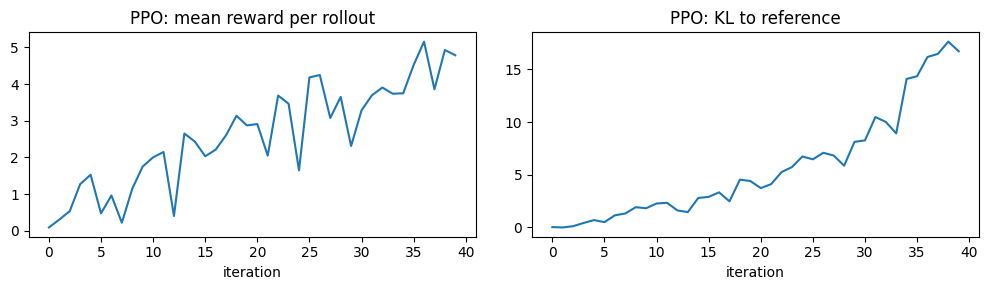

In [9]:
log = pd.DataFrame(ppo_log)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(log["iteration"], log["reward"]); ax[0].set_title("PPO: mean reward per rollout"); ax[0].set_xlabel("iteration")
ax[1].plot(log["iteration"], log["kl"]);     ax[1].set_title("PPO: KL to reference");         ax[1].set_xlabel("iteration")
plt.tight_layout(); plt.show()

## 6. GRPO: Group Relative Policy Optimization (TRL)

GRPO (DeepSeekMath, used for DeepSeek-R1) removes the value network. For each prompt it samples `num_generations` completions, scores them with one or more **reward functions**, and uses the group-normalized reward as the advantage of every token in that completion. Reward functions are plain Python callables, which makes GRPO popular for verifiable rewards (correct math answer, passing unit tests, valid format). Here the reward function wraps our sentiment model.

Notes on the configuration:
- `per_device_train_batch_size` counts completions, so 16 completions with `num_generations=4` means 4 prompts per step.
- TRL's default is `beta=0.0` (no KL term, no reference model in memory). We set `beta=0.05` to keep a KL penalty comparable to PPO.

In [10]:
from trl import GRPOConfig, GRPOTrainer

def positive_sentiment(prompts, completions, **kwargs):
    return sentiment_reward([p + c for p, c in zip(prompts, completions)])

grpo_ds = Dataset.from_dict({"prompt": train_prompts})

set_seed(SEED)
grpo_policy = load_sft()

grpo_args = GRPOConfig(
    output_dir="./align_grpo",
    num_generations=4,               # group size G
    per_device_train_batch_size=16,  # completions per step (= 4 prompts x 4 generations)
    max_completion_length=24,
    temperature=1.0,
    learning_rate=1e-5,
    beta=0.05,                       # KL penalty to the reference
    max_steps=60,
    logging_steps=10,
    save_strategy="no",
    bf16=USE_BF16,
    report_to="none",
    seed=SEED,
)

grpo_trainer = GRPOTrainer(
    model=grpo_policy,
    reward_funcs=positive_sentiment,
    args=grpo_args,
    train_dataset=grpo_ds,
    processing_class=tok,
)

t0 = time.time()
grpo_trainer.train()
grpo_seconds = time.time() - t0

evaluate_policy(grpo_policy, "GRPO", grpo_seconds);

Step,Training Loss
10,0.012250
20,0.044069
30,0.007840
40,0.007229
50,0.017496
60,0.013810


{'method': 'GRPO', 'mean reward': np.float64(1.316723961615935), '% positive': np.float64(68.75), 'KL to reference': np.float64(0.5191360549069941), 'train time (s)': 264.4}


## 7. Comparison

All methods start from the same SFT model and are evaluated on the same 64 held-out prompts with the same sampling seed. Higher reward and % positive mean the alignment objective was met; the KL column shows the price paid in drift from the SFT model. With these small CPU budgets the numbers are indicative only: each method's hyperparameters (β, learning rate, steps) shift its position on the reward-vs-KL trade-off.

The budgets also differ: PPO sees 40 × 32 = 1,280 prompts, GRPO 60 × 4 = 240 prompts (4 samples each), and DPO 3 epochs over 230 fixed pairs.

**Reading the saved run:** all three methods raise the reward over the SFT model. PPO gets the highest reward but also drifts furthest from the reference (KL ≈ 21) because its KL penalty is weak relative to the reward scale; its samples show the beginnings of reward hacking (stacked superlatives). DPO reaches a high reward at moderate KL from a fixed dataset of 230 pairs. GRPO, with the smallest budget and a stronger KL term, stays closest to the reference; give it more `max_steps` or a lower `beta` to push the reward higher.

In [11]:
results_df = pd.DataFrame(RESULTS).set_index("method")
results_df.style.format({"mean reward": "{:.2f}", "% positive": "{:.1f}", "KL to reference": "{:.2f}", "train time (s)": "{:.1f}"})

,mean reward,% positive,KL to reference,train time (s)
method,,,,
SFT model (no alignment),0.32,54.7,0.00,0.0
DPO,3.27,87.5,3.94,268.5
PPO,4.59,95.3,20.82,1279.9
GRPO,1.32,68.8,0.52,264.4


In [12]:
# Same prompts, one sampled completion per method
for i in range(4):
    print(f"PROMPT: {eval_prompts[i]!r}")
    for method, texts in SAMPLES.items():
        print(f"  {method:>26}: {texts[i]!r}")
    print()

PROMPT: '  When I unsuspectedly rented A'
    SFT model (no alignment): ' Tale of Two Sisters and wanted it here on DVD I saw it now and had an expectation for what the film would have'
                         DPO: ' Tale of Two Sisters and wanted it to be one of my all-time favourite movies - I loved the sound of it'
                         PPO: ' Tale of Two Sisters and loved it here is one time 10! A fun, family comedy heartwarming film that will entertain'
                        GRPO: ' Tale of Two Sisters and wanted it here on DVD I saw it now and had an appreciation for both the sound of an'

PROMPT: 'This is the latest entry in the long'
    SFT model (no alignment): ' line of WTB shows to come out of Crystal Lake. Not only has this meant a lot for JABS fans since'
                         DPO: ' line of WTB shows to come out of Crystal Lake. It was an animation that served the musical needs of Hollywood.'
                         PPO: ' and rich WTB series that is a dark mes

## 8. Takeaways and Next Steps

- **DPO** is the simplest to run: an offline dataset, a standard training loop, and only two models in memory. It cannot explore beyond the responses in its pairs.
- **PPO** is the most general but also the heaviest: four models, many hyperparameters, and online generation in every step.
- **GRPO** keeps online exploration but replaces the critic with group statistics, and accepts any Python function as a reward, which is why it is widely used for reasoning tasks with checkable answers.
- **Reward hacking:** a policy optimizes the reward model, not the intent behind it. Watch the samples and the KL, not only the reward. Repetitive superlatives are the typical failure in this task.

To scale up: swap `lvwerra/gpt2-imdb` for an instruction-tuned model (e.g., a 0.5B to 1.5B chat model), use a real preference dataset for DPO, add `peft_config=LoraConfig(...)` to `DPOTrainer` / `GRPOTrainer` to train LoRA adapters only, and run on a GPU (TRL's GRPO can also use vLLM for fast generation).